### IMPORTING LIBRARIES

In [3]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier


## LOADING DATASET

In [4]:
df = pd.read_csv("titanic.csv")
df.shape

(887, 8)

In [5]:
df.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


### Checking missing values

In [6]:
df.isna().sum()

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

### Encoding Sex column

In [7]:
df["Sex"]=df["Sex"].map({"male":1,"female":2})
df.head(3)

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,1,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,2,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,2,26.0,0,0,7.9250


In [8]:
# droping 'Name' column which is not useful in determining the survival rate
df=df.drop(columns=["Name"])
df.head(2)


,Survived,Pclass,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,1,22.0,1,0,7.2500
1,1,1,2,38.0,1,0,71.2833


### Data Visualization

In [9]:
df["Survived"].value_counts().values

array([545, 342])

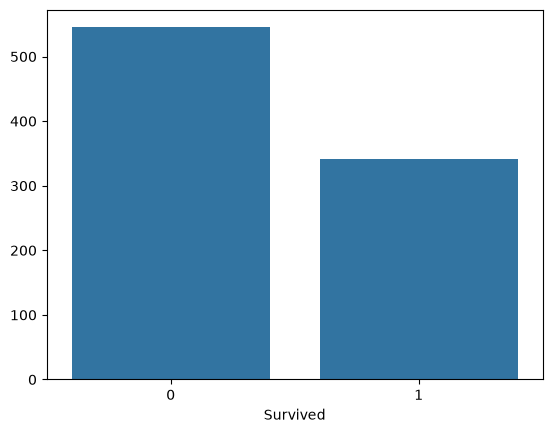

In [10]:
## SURVIVED VS NOT SURVIED
sns.barplot(x=df["Survived"].value_counts().index,y=df["Survived"].value_counts().values)
plt.show()

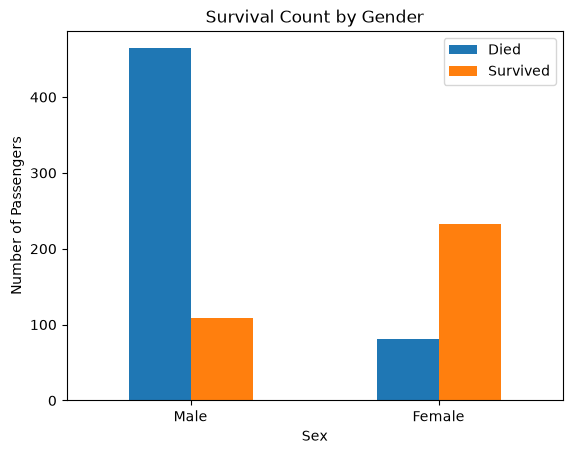

In [11]:
### SURVIVAL BY GENDER
g=df.groupby("Sex")["Survived"].value_counts()
g.unstack().plot(kind="bar")

plt.title("Survival Count by Gender")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.xticks([0,1],["Male","Female"])
plt.xticks(rotation=0)
plt.legend(["Died", "Survived"])

plt.show()

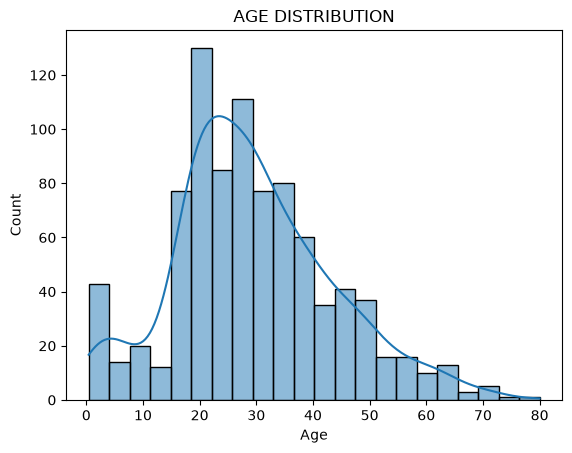

In [12]:
###  Age Distribution

sns.histplot(df,x="Age",kde=True)
plt.title("AGE DISTRIBUTION")
plt.show()

In [13]:
df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'Siblings/Spouses Aboard',
       'Parents/Children Aboard', 'Fare'],
      dtype='str')

In [14]:
df["Fare"].value_counts()

Fare
8.0500     43
13.0000    42
7.8958     36
7.7500     33
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64

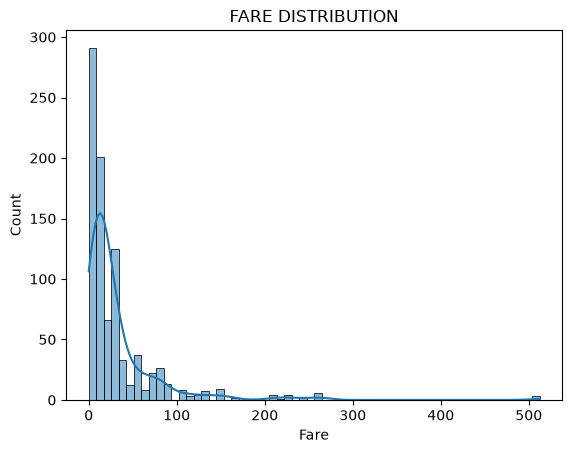

In [15]:
## Fare distribution

sns.histplot(df,x="Fare",kde=True)
plt.title("FARE DISTRIBUTION")
plt.show()

## Train Test Split

In [16]:
X=df.drop(columns=["Survived"])
y=df["Survived"]

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)



### MODEL TRAINING USING DECISION TREE

In [17]:
dt=DecisionTreeClassifier()
dt.fit(X_train,y_train)

## prediction

y_pred = dt.predict(X_test)

## model evaluation report

report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.80      0.75      0.77       111
           1       0.62      0.69      0.65        67

    accuracy                           0.72       178
   macro avg       0.71      0.72      0.71       178
weighted avg       0.73      0.72      0.73       178



<Axes: >

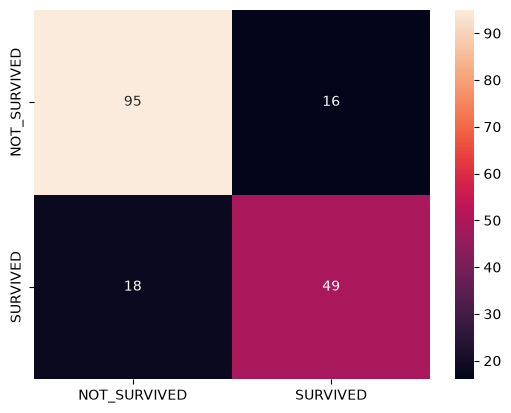

In [22]:
### confusion matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,xticklabels=["NOT_SURVIVED","SURVIVED"],yticklabels=["NOT_SURVIVED","SURVIVED"])

### MODEL TRAINING USING RANDOM FOREST

In [24]:
rf=RandomForestClassifier()
rf.fit(X_train,y_train)

## prediction

y_pred = rf.predict(X_test)

## model evaluation report

report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.83      0.81      0.82       111
           1       0.70      0.72      0.71        67

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.78      0.78      0.78       178



<Axes: >

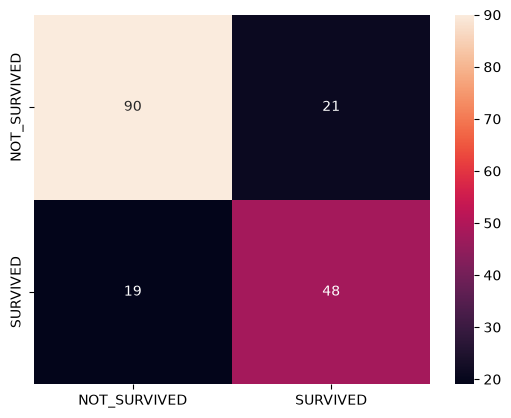

In [25]:
### confusion matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,xticklabels=["NOT_SURVIVED","SURVIVED"],yticklabels=["NOT_SURVIVED","SURVIVED"])

### MODEL TRAING USING GRADIENT BOOSTING CLASSIFIER

In [26]:
gb=GradientBoostingClassifier()
gb.fit(X_train,y_train)

## prediction

y_pred = gb.predict(X_test)

## model evaluation report

report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.85      0.86      0.85       111
           1       0.76      0.75      0.75        67

    accuracy                           0.81       178
   macro avg       0.80      0.80      0.80       178
weighted avg       0.81      0.81      0.81       178



<Axes: >

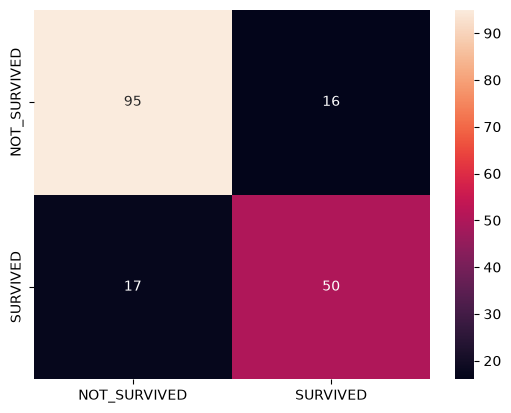

In [27]:
### confusion matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,xticklabels=["NOT_SURVIVED","SURVIVED"],yticklabels=["NOT_SURVIVED","SURVIVED"])

##### SUMMARY:If you compare classification report across decision tree, random forest and gradient boost, you will notice slight improvement in precision, recall and accuracy when we use gradient boosting